## Step 1 — Load and merge the data
`demand.csv` and `inventory.csv` are merged on `week_start` and `part_id` (inner join), and the part master data from `parts.csv` is added with a left join.

# Inventory Analytics for EV Spare Parts
**Course:** Programming for Management Studies (Summer 2026)

**Central question:** Can a forecasting method with low statistical error still create high inventory cost?

This notebook analyzes 78 weeks (2024-01-01 to 2025-06-23) of weekly demand and inventory data for 24 EV spare parts. It follows five steps:
1. Load and merge the three data files
2. Compute the inventory variables and KPIs (fill rate, stockout rate, holding and stockout cost)
3. Explore demand patterns by part, category and region
4. Compare three forecasting methods with error-based metrics (MSE, MAE, MAPE) and cost-based metrics (overage and underage cost)
5. Build safety stocks, reorder points and the file `reorder_recommendations.csv`

Only techniques from the course are used: pandas (merge, groupby, agg, pivot_table, apply, sorting), matplotlib, NumPy, and plain Python functions and loops.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# load the three input files
parts = pd.read_csv('parts.csv')
demand = pd.read_csv('demand.csv')
inventory = pd.read_csv('inventory.csv')

print('parts:', parts.shape)
print('demand:', demand.shape)
print('inventory:', inventory.shape)

parts: (24, 10)
demand: (1872, 6)
inventory: (1872, 4)


In [2]:
# merge weekly demand with weekly inventory, then attach part information
df = pd.merge(demand, inventory, on=['week_start', 'part_id'], how='inner')
df = pd.merge(df, parts, on='part_id', how='left')
print('merged table:', df.shape)
df.head()

merged table: (1872, 17)


,week_start,part_id,units_demanded,service_center_region,vehicle_type,service_campaign,stock_on_hand,replenishment,part_name,category,unit_cost,unit_price,supplier,lead_time_days,demand_trend,holding_cost_per_unit_week,stockout_cost_per_unit
0,2024-01-01,P001,3,West,Compact EV,0,25,0,Battery Module A,Battery System,820,1150,VoltCore GmbH,21,Increasing,4.92,847.5
1,2024-01-08,P001,3,West,Compact EV,0,22,0,Battery Module A,Battery System,820,1150,VoltCore GmbH,21,Increasing,4.92,847.5
2,2024-01-15,P001,4,Central,Compact EV,1,19,0,Battery Module A,Battery System,820,1150,VoltCore GmbH,21,Increasing,4.92,847.5
3,2024-01-22,P001,4,North,Compact EV,0,15,30,Battery Module A,Battery System,820,1150,VoltCore GmbH,21,Increasing,4.92,847.5
4,2024-01-29,P001,4,West,Compact EV,0,41,0,Battery Module A,Battery System,820,1150,VoltCore GmbH,21,Increasing,4.92,847.5


## Step 2 — Inventory variables
Following the assignment (Section 3), for every part-week we compute:
- `available_inventory = stock_on_hand + replenishment`
- `units_fulfilled = min(available_inventory, units_demanded)`
- `unmet_demand = max(units_demanded - available_inventory, 0)`
- `ending_stock = max(available_inventory - units_demanded, 0)`
- `stockout = 1` if `unmet_demand > 0`, otherwise `0`

From these we derive the weekly holding cost, stockout cost and revenue.

In [3]:
df['available_inventory'] = df['stock_on_hand'] + df['replenishment']

def fulfilled_units(row):
    # demand can only be served from the inventory that is available
    return min(row['available_inventory'], row['units_demanded'])

def stockout_flag(unmet):
    if unmet > 0:
        return 1
    return 0

df['units_fulfilled'] = df.apply(fulfilled_units, axis=1)
df['unmet_demand'] = df['units_demanded'] - df['units_fulfilled']
df['ending_stock'] = df['available_inventory'] - df['units_demanded']
df.loc[df['ending_stock'] < 0, 'ending_stock'] = 0
df['stockout'] = df['unmet_demand'].apply(stockout_flag)

# weekly costs and revenue
df['holding_cost'] = df['ending_stock'] * df['holding_cost_per_unit_week']
df['stockout_cost'] = df['unmet_demand'] * df['stockout_cost_per_unit']
df['revenue'] = df['units_fulfilled'] * df['unit_price']

df[['week_start', 'part_id', 'units_demanded', 'available_inventory',
    'units_fulfilled', 'unmet_demand', 'ending_stock', 'stockout']].head()

,week_start,part_id,units_demanded,available_inventory,units_fulfilled,unmet_demand,ending_stock,stockout
0,2024-01-01,P001,3,25,3,0,22,0
1,2024-01-08,P001,3,22,3,0,19,0
2,2024-01-15,P001,4,19,4,0,15,0
3,2024-01-22,P001,4,45,4,0,41,0
4,2024-01-29,P001,4,41,4,0,37,0


## Step 3 — Demand patterns and inventory KPIs

In [4]:
# overall performance of the warehouse over the 78 weeks
total_demand = df['units_demanded'].sum()
total_unmet = df['unmet_demand'].sum()
print('total demand (units):', total_demand)
print('unmet demand (units):', total_unmet)
print('fill rate:', round(1 - total_unmet / total_demand, 4))
print('stockout rate (share of part-weeks):', round(df['stockout'].mean(), 4))
print('total holding cost (EUR):', round(df['holding_cost'].sum(), 0))
print('total stockout cost (EUR):', round(df['stockout_cost'].sum(), 0))
print('total revenue (EUR):', df['revenue'].sum())

total demand (units): 25034
unmet demand (units): 558
fill rate: 0.9777
stockout rate (share of part-weeks): 0.0358
total holding cost (EUR): 45862.0
total stockout cost (EUR): 136522.0
total revenue (EUR): 5707900


In [5]:
# KPIs per part
part_kpi = df.groupby(['part_id', 'part_name', 'category']).agg(
    total_demand=('units_demanded', 'sum'),
    mean_weekly_demand=('units_demanded', 'mean'),
    total_unmet=('unmet_demand', 'sum'),
    stockout_rate=('stockout', 'mean'),
    avg_ending_stock=('ending_stock', 'mean'),
    holding_cost=('holding_cost', 'sum'),
    stockout_cost=('stockout_cost', 'sum')).reset_index()
part_kpi['fill_rate'] = 1 - part_kpi['total_unmet'] / part_kpi['total_demand']

print('--- parts with the most frequent stockouts ---')
cols = ['part_id', 'part_name', 'stockout_rate', 'fill_rate', 'total_unmet', 'stockout_cost']
print(part_kpi.sort_values('stockout_rate', ascending=False)[cols].head(5).round(3).to_string(index=False))

print('--- parts with systematically high ending stock ---')
cols = ['part_id', 'part_name', 'avg_ending_stock', 'holding_cost', 'stockout_rate']
print(part_kpi.sort_values('avg_ending_stock', ascending=False)[cols].head(5).round(2).to_string(index=False))

--- parts with the most frequent stockouts ---
part_id                       part_name  stockout_rate  fill_rate  total_unmet  stockout_cost
   P002           Battery Cooling Plate          0.167      0.927           79        16037.0
   P008 Regenerative Brake Control Unit          0.128      0.929          104        31590.0
   P004          Charging Port Assembly          0.115      0.903          109        27141.0
   P016     Motor Rotor Position Sensor          0.115      0.954           90         7920.0
   P011                Cabin PTC Heater          0.103      0.959           55        10065.0
--- parts with systematically high ending stock ---
part_id                  part_name  avg_ending_stock  holding_cost  stockout_rate
   P019  Low-Voltage Connector Set             41.77        358.38           0.00
   P005          AC Charging Cable             41.05       1440.90           0.00
   P017         Wheel Speed Sensor             38.38        568.86           0.00
   P010  

In [6]:
# KPIs per category
cat_kpi = df.groupby('category').agg(
    total_demand=('units_demanded', 'sum'),
    revenue=('revenue', 'sum'),
    holding_cost=('holding_cost', 'sum'),
    stockout_cost=('stockout_cost', 'sum'),
    stockout_rate=('stockout', 'mean'))
cat_kpi['fill_rate'] = 1 - df.groupby('category')['unmet_demand'].sum() / df.groupby('category')['units_demanded'].sum()
cat_kpi.round(2)

,total_demand,revenue,holding_cost,stockout_cost,stockout_rate,fill_rate
category,,,,,,
Battery System,3008,952565,10929.95,16320.0,0.05,0.97
Brake System,2497,615402,3087.69,31590.0,0.06,0.96
Cables and Connectors,6033,1104393,5497.20,18067.5,0.02,0.99
Charging System,2990,681310,3877.10,27379.5,0.04,0.96
Control Units,253,194340,2907.00,4448.5,0.03,0.97
Electric Motor,524,78600,646.17,0.0,0.00,1.00
Power Electronics,1056,774080,9454.92,20253.0,0.03,0.97
Sensors,3702,337795,1477.56,7920.0,0.06,0.98
Thermal Management,4971,969415,7984.05,10543.5,0.02,0.99


In [7]:
# demand by region and effect of service campaigns (pivot table)
region_pivot = pd.pivot_table(df, values='units_demanded',
                              index='service_center_region',
                              columns='service_campaign', aggfunc='mean')
region_pivot.columns = ['no campaign', 'campaign']
print(region_pivot.round(2).to_string())
print()
print('average weekly demand without campaign:', round(df[df['service_campaign'] == 0]['units_demanded'].mean(), 2))
print('average weekly demand with campaign:   ', round(df[df['service_campaign'] == 1]['units_demanded'].mean(), 2))

                       no campaign  campaign
service_center_region                       
Central                      13.46     15.75
East                         12.43     15.07
North                        12.79     17.76
South                        13.87     14.39
West                         12.21     19.74

average weekly demand without campaign: 12.95
average weekly demand with campaign:    16.54


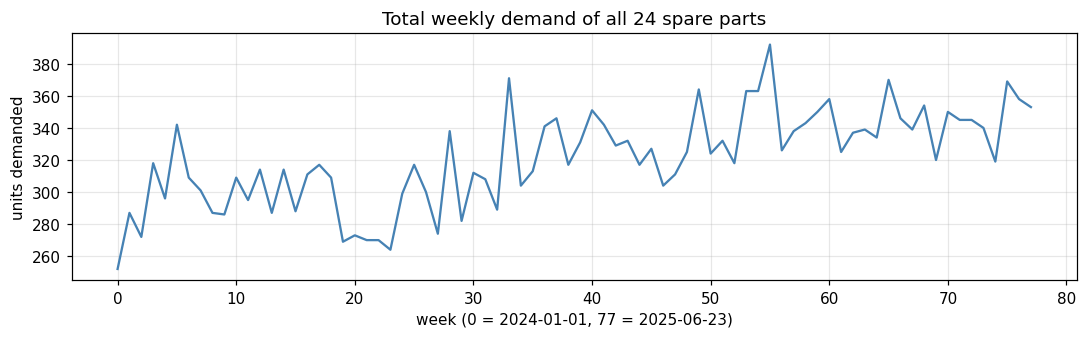

In [8]:
# Figure 1: total weekly demand over time
weekly_total = df.groupby('week_start')['units_demanded'].sum()
plt.figure(figsize=(10, 3.2))
plt.plot(weekly_total.values, color='steelblue')
plt.title('Total weekly demand of all 24 spare parts')
plt.xlabel('week (0 = 2024-01-01, 77 = 2025-06-23)')
plt.ylabel('units demanded')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig1_weekly_demand.png', dpi=200)
plt.show()

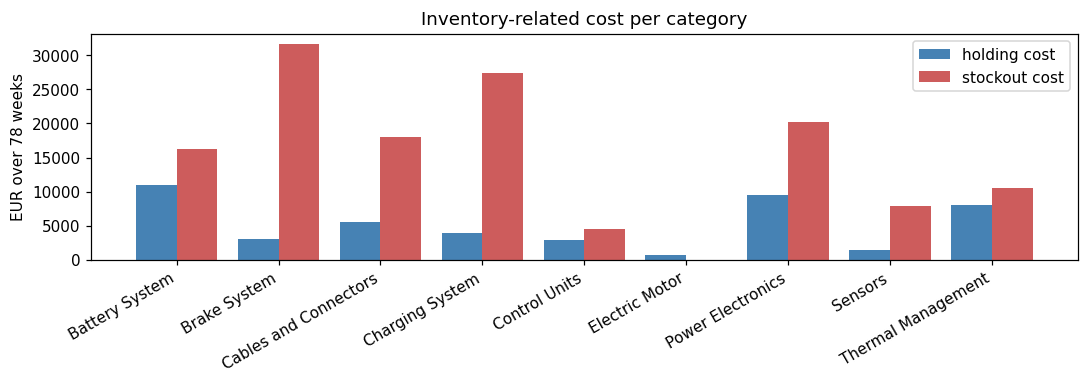

In [9]:
# Figure 2: holding cost vs stockout cost per category
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(cat_kpi.index))
ax.bar(x - 0.2, cat_kpi['holding_cost'], width=0.4, label='holding cost', color='steelblue')
ax.bar(x + 0.2, cat_kpi['stockout_cost'], width=0.4, label='stockout cost', color='indianred')
ax.set_xticks(x)
ax.set_xticklabels(cat_kpi.index, rotation=30, ha='right')
ax.set_ylabel('EUR over 78 weeks')
ax.set_title('Inventory-related cost per category')
ax.legend()
plt.tight_layout()
plt.savefig('fig2_costs_by_category.png', dpi=200)
plt.show()

## Step 4 — Forecasting: error-based vs cost-based evaluation
Three simple methods are implemented as plain Python functions:
- **Naive:** forecast = demand of the previous week
- **Moving average (4 weeks):** forecast = mean of the last 4 weeks
- **Exponential smoothing (alpha = 0.3):** level is updated week by week in a loop

**Evaluation design.** The last 12 weeks are used as the test period. For every part and week, the forecast is produced only from earlier weeks (rolling one-step-ahead). Because spare parts are discrete, the forecast is rounded to integer units before it is used for the cost evaluation.

**Cost assumptions.** If the integer forecast is *above* actual demand (overage), each extra unit is held one week and costs `holding_cost_per_unit_week`. If it is *below* actual demand (underage), each missing unit costs `stockout_cost_per_unit`.

In [10]:
def naive_forecast(history):
    # demand of the last observed week
    return history[-1]

def moving_average_forecast(history, window=4):
    # mean of the last <window> weeks
    recent = history[-window:]
    return sum(recent) / len(recent)

def exp_smoothing_forecast(history, alpha=0.3):
    # update the level week by week: level = alpha*demand + (1-alpha)*level
    level = history[0]
    for value in history[1:]:
        level = alpha * value + (1 - alpha) * level
    return level

methods = {'Naive': naive_forecast,
           'MovingAvg4': moving_average_forecast,
           'ExpSmooth': exp_smoothing_forecast}

TEST_WEEKS = 12
weeks = sorted(df['week_start'].unique())
print('training weeks:', len(weeks) - TEST_WEEKS, '| test weeks:', TEST_WEEKS)

training weeks: 66 | test weeks: 12


In [11]:
# rolling one-step-ahead evaluation for every part, method and test week
records = []
for part in parts['part_id']:
    series = df[df['part_id'] == part].sort_values('week_start')
    values = list(series['units_demanded'])
    h = series['holding_cost_per_unit_week'].iloc[0]
    p = series['stockout_cost_per_unit'].iloc[0]
    for name in methods:
        method = methods[name]
        for i in range(len(weeks) - TEST_WEEKS, len(weeks)):
            history = values[:i]              # only data before week i
            actual = values[i]
            fc = method(history)
            fc_int = int(round(fc))           # integer units for inventory decisions
            error = fc - actual
            records.append({'part_id': part, 'method': name, 'week': weeks[i],
                            'actual': actual, 'forecast': fc,
                            'abs_error': abs(error), 'sq_error': error ** 2,
                            'overage_cost': max(fc_int - actual, 0) * h,
                            'underage_cost': max(actual - fc_int, 0) * p})
fc_df = pd.DataFrame(records)
print('forecast evaluations:', fc_df.shape[0], '(24 parts x 3 methods x 12 weeks)')

forecast evaluations: 864 (24 parts x 3 methods x 12 weeks)


In [12]:
# error-based evaluation: MSE, MAE, MAPE (zero-demand weeks excluded for MAPE)
error_eval = fc_df.groupby('method').agg(MSE=('sq_error', 'mean'), MAE=('abs_error', 'mean'))
nonzero = fc_df[fc_df['actual'] > 0].copy()
nonzero['ape'] = nonzero['abs_error'] / nonzero['actual']
error_eval['MAPE_pct'] = nonzero.groupby('method')['ape'].mean() * 100

# cost-based evaluation: overage, underage and total cost
cost_eval = fc_df.groupby('method').agg(overage_cost=('overage_cost', 'sum'),
                                        underage_cost=('underage_cost', 'sum'))
cost_eval['total_cost'] = cost_eval['overage_cost'] + cost_eval['underage_cost']

print('--- error-based evaluation ---')
print(error_eval.round(3).to_string())
print()
print('--- cost-based evaluation (EUR, 12 test weeks) ---')
print(cost_eval.round(0).to_string())

--- error-based evaluation ---
               MSE    MAE  MAPE_pct
method                             
ExpSmooth   15.640  3.009    34.208
MovingAvg4  16.895  3.108    34.877
Naive       25.552  3.747    41.958

--- cost-based evaluation (EUR, 12 test weeks) ---
            overage_cost  underage_cost  total_cost
method                                             
ExpSmooth          420.0        82775.0     83195.0
MovingAvg4         453.0        86147.0     86600.0
Naive              545.0       100770.0    101316.0


In [13]:
# does the best method by error also win by cost? (per part)
per_part = fc_df.groupby(['part_id', 'method']).agg(
    MAE=('abs_error', 'mean'),
    overage=('overage_cost', 'sum'),
    underage=('underage_cost', 'sum')).reset_index()
per_part['cost'] = per_part['overage'] + per_part['underage']

best_by_error = per_part.sort_values('MAE').groupby('part_id').head(1)
best_by_cost = per_part.sort_values('cost').groupby('part_id').head(1)
compare = pd.merge(best_by_error[['part_id', 'method']],
                   best_by_cost[['part_id', 'method']],
                   on='part_id', suffixes=('_best_error', '_best_cost'))
compare['same'] = compare['method_best_error'] == compare['method_best_cost']
print('parts where the most precise method is also the cheapest:', compare['same'].sum(), 'of 24')
print()
print(compare[compare['same'] == False].to_string(index=False))

parts where the most precise method is also the cheapest: 16 of 24

part_id method_best_error method_best_cost  same
   P012         ExpSmooth       MovingAvg4 False
   P020         ExpSmooth       MovingAvg4 False
   P023        MovingAvg4        ExpSmooth False
   P001         ExpSmooth       MovingAvg4 False
   P017             Naive        ExpSmooth False
   P004         ExpSmooth       MovingAvg4 False
   P019        MovingAvg4        ExpSmooth False
   P016         ExpSmooth       MovingAvg4 False


In [14]:
# example: Battery Module A (P001) - lowest MAE and lowest cost disagree
example = per_part[per_part['part_id'] == 'P001'].sort_values('MAE')
print(example[['method', 'MAE', 'overage', 'underage', 'cost']].round(2).to_string(index=False))

    method  MAE  overage  underage    cost
 ExpSmooth 1.63    44.28    7627.5 7671.78
MovingAvg4 1.71    63.96    6780.0 6843.96
     Naive 1.83    63.96    7627.5 7691.46


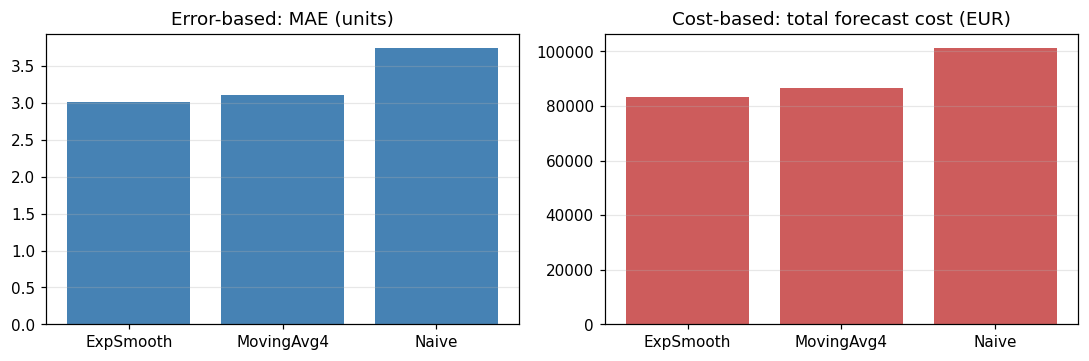

In [15]:
# Figure 3: error ranking vs cost ranking of the three methods
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(error_eval.index, error_eval['MAE'], color='steelblue')
axes[0].set_title('Error-based: MAE (units)')
axes[1].bar(cost_eval.index, cost_eval['total_cost'], color='indianred')
axes[1].set_title('Cost-based: total forecast cost (EUR)')
for ax in axes:
    ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig3_error_vs_cost.png', dpi=200)
plt.show()

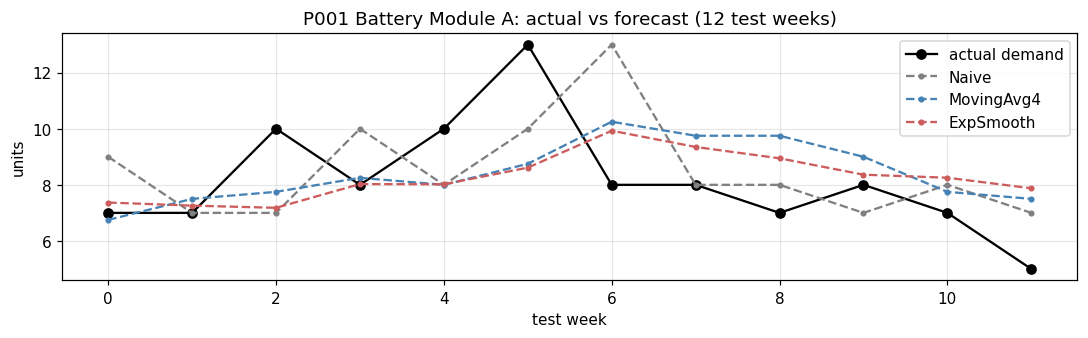

In [16]:
# Figure 4 (appendix): actual demand vs the three forecasts for P001 in the test weeks
p001 = fc_df[fc_df['part_id'] == 'P001']
plt.figure(figsize=(10, 3.2))
plt.plot(range(TEST_WEEKS), p001[p001['method'] == 'Naive']['actual'].values,
         color='black', marker='o', label='actual demand')
colors = {'Naive': 'gray', 'MovingAvg4': 'steelblue', 'ExpSmooth': 'indianred'}
for name in methods:
    sub = p001[p001['method'] == name]
    plt.plot(range(TEST_WEEKS), sub['forecast'].values, marker='.',
             linestyle='--', color=colors[name], label=name)
plt.title('P001 Battery Module A: actual vs forecast (12 test weeks)')
plt.xlabel('test week')
plt.ylabel('units')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig4_p001_forecasts.png', dpi=200)
plt.show()

## Step 5 — Safety stock, reorder point and reorder recommendations
Assumptions (stated explicitly):
- `forecasted_weekly_demand` = exponential-smoothing forecast over the full history, rounded to integer units
- lead time in weeks = `lead_time_days / 7`
- `safety_stock = ceil(1.65 * std_weekly_demand * sqrt(lead_time_weeks))` (z = 1.65, about a 95% service level)
- `reorder_point = ceil(forecast * lead_time_weeks) + safety_stock`
- `current_stock` = ending stock of the last observed week (2025-06-23)
- if `current_stock <= reorder_point`, order up to `reorder_point + forecast` (one extra week of cover)

Recommendation rules distinguish the four situations required by the assignment: immediate replenishment, high stockout risk (historical stockout rate >= 10%), excess inventory (stock above 1.5x the reorder point and more than 6 weeks of cover), and expensive low-demand parts (unit cost >= 300 EUR and mean demand below 5 units/week).

In [17]:
last_week = max(df['week_start'])
rows = []
for i in range(len(parts)):
    part = parts.iloc[i]
    sub = df[df['part_id'] == part['part_id']].sort_values('week_start')
    values = list(sub['units_demanded'])

    forecast = int(round(exp_smoothing_forecast(values)))
    lead_time_weeks = part['lead_time_days'] / 7
    sigma = sub['units_demanded'].std()
    safety_stock = math.ceil(1.65 * sigma * math.sqrt(lead_time_weeks))
    reorder_point = math.ceil(forecast * lead_time_weeks) + safety_stock
    current_stock = int(sub[sub['week_start'] == last_week]['ending_stock'].iloc[0])
    stockout_rate = sub['stockout'].mean()
    mean_demand = sub['units_demanded'].mean()

    if current_stock <= reorder_point:
        order_qty = reorder_point + forecast - current_stock
        if stockout_rate >= 0.10:
            recommendation = 'Order now - high stockout risk'
        else:
            recommendation = 'Order now - below reorder point'
    else:
        order_qty = 0
        if part['unit_cost'] >= 300 and mean_demand < 5:
            recommendation = 'Expensive low-demand - do not overstock'
        elif current_stock > 1.5 * reorder_point and current_stock > 6 * forecast:
            recommendation = 'Excess inventory - reduce stock'
        else:
            recommendation = 'Adequate - monitor'

    rows.append({'part_id': part['part_id'], 'part_name': part['part_name'],
                 'category': part['category'], 'current_stock': current_stock,
                 'forecasted_weekly_demand': forecast,
                 'lead_time_days': part['lead_time_days'],
                 'safety_stock': safety_stock, 'reorder_point': reorder_point,
                 'recommended_order_quantity': order_qty,
                 'recommendation': recommendation})

reorder = pd.DataFrame(rows)
reorder.to_csv('reorder_recommendations.csv', index=False)
print(reorder['recommendation'].value_counts().to_string())
reorder

recommendation
Order now - below reorder point            9
Adequate - monitor                         7
Order now - high stockout risk             5
Expensive low-demand - do not overstock    2
Excess inventory - reduce stock            1


,part_id,part_name,category,current_stock,forecasted_weekly_demand,lead_time_days,safety_stock,reorder_point,recommended_order_quantity,recommendation
0,P001,Battery Module A,Battery System,30,7,21,8,29,0,Adequate - monitor
1,P002,Battery Cooling Plate,Battery System,0,19,14,12,50,69,Order now - high stockout risk
2,P003,Battery Management Sensor,Battery System,21,6,14,6,18,0,Adequate - monitor
3,P004,Charging Port Assembly,Charging System,15,22,21,17,83,90,Order now - high stockout risk
4,P005,AC Charging Cable,Cables and Connectors,60,24,7,11,35,0,Adequate - monitor
5,P006,DC Fast-Charge Connector,Charging System,0,14,14,9,37,51,Order now - below reorder point
6,P007,Brake Wear Sensor,Brake System,14,14,7,7,21,21,Order now - below reorder point
7,P008,Regenerative Brake Control Unit,Brake System,45,10,21,18,48,13,Order now - high stockout risk
8,P009,Coolant Pump,Thermal Management,10,17,14,12,46,53,Order now - below reorder point
9,P010,Heat Exchanger,Thermal Management,50,6,21,11,29,0,Excess inventory - reduce stock


## Conclusion
**Yes — a forecasting method with low statistical error can still create high inventory cost.** Exponential smoothing has the best MSE, MAE and MAPE and also the lowest total cost overall, but for 8 of the 24 parts the cheapest method is *not* the most precise one (e.g. P001 Battery Module A: exponential smoothing wins on MAE, yet the 4-week moving average is about 11% cheaper). The reason is the strong cost asymmetry: one week of holding costs cents to a few euros per unit, while one unit of unmet demand costs 34-848 EUR. Forecasts should therefore be selected and buffered based on cost, not on statistical precision alone.